<a href="https://colab.research.google.com/github/Abdoulaye279/Machine-Learning-and-AI-for-Physics/blob/main/PulseNoise_and_AlphaProton_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Pulse or noise?
A detector channel records real particle pulses and also electronic noise (pulse_noise.csv). For each
recorded signal we know its amplitude amplitude_mV and its width width_ns. The label is label_pulse:
1 for a real pulse and 0 for noise. We want to classify the signals with logistic regression.

In [ ]:
# Given parameters
FILE            = "data/pulse_noise.csv"
FEATURES        = ["amplitude_mV", "width_ns"]
TARGET          = "label_pulse"
TEST_SIZE       = 0.25
ETA             = 0.1
N_EPOCHS        = 1000

### Part A: Data


In [ ]:
df = pd.read_csv(FILE)
print("shape:", df.shape)
print(df.isna().sum())
print("duplicated rows:", df.duplicated().sum())

clean = df.drop_duplicates().dropna()
clean = clean[(clean["amplitude_mV"] > 0) & (clean["width_ns"] > 0)]
print(clean[TARGET].value_counts())

shape: (803, 4)
event_id        0
amplitude_mV    4
width_ns        3
label_pulse     0
dtype: int64
duplicated rows: 3
label_pulse
0    453
1    335
Name: count, dtype: int64


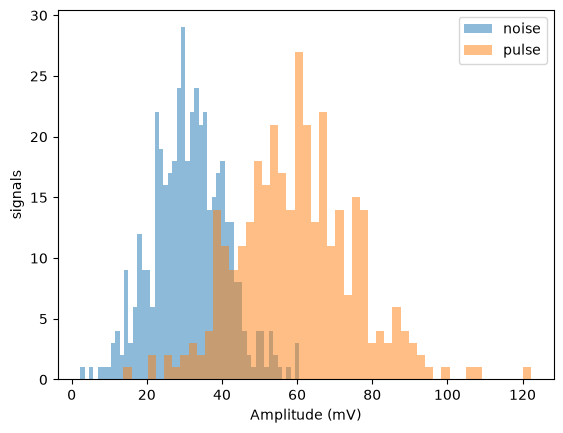

training: 591   test: 197


In [ ]:
from sklearn.model_selection import train_test_split

noise = clean[clean[TARGET] == 0]
pulse = clean[clean[TARGET] == 1]

plt.hist(noise["amplitude_mV"], bins=50, alpha=0.5, label="noise")
plt.hist(pulse["amplitude_mV"], bins=50, alpha=0.5, label="pulse")
plt.xlabel("Amplitude (mV)")
plt.ylabel("signals")
plt.legend()
plt.show()

train, test = train_test_split(clean, test_size=TEST_SIZE, stratify=clean[TARGET], random_state=42)
ytr = train[TARGET]
yte = test[TARGET]
print("training:", len(train), "  test:", len(test))

### Part B: Logistic regression


In [ ]:
from sklearn.linear_model import LogisticRegression

m1 = LogisticRegression()
m1.fit(train[["amplitude_mV"]], ytr)
b0 = m1.intercept_[0]
b1 = m1.coef_[0][0]
A50 = -b0 / b1
print("b0 =", b0)
print("b1 =", b1, "per mV")
print("p = 0.5 at A =", A50, "mV")

b0 = -8.868906457160081
b1 = 0.1977241399826768 per mV
p = 0.5 at A = 44.854950224778385 mV


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

m2 = LogisticRegression()
m2.fit(train[["amplitude_mV", "width_ns"]], ytr)
print("two inputs: b0 =", m2.intercept_[0], " b1 =", m2.coef_[0][0], " b2 =", m2.coef_[0][1])

pred1 = m1.predict(test[["amplitude_mV"]])
pred2 = m2.predict(test[["amplitude_mV", "width_ns"]])

print("amplitude only   : accuracy", round(accuracy_score(yte, pred1), 3), " precision", round(precision_score(yte, pred1), 3), " recall", round(recall_score(yte, pred1), 3))
print(confusion_matrix(yte, pred1))
print("amplitude + width: accuracy", round(accuracy_score(yte, pred2), 3), " precision", round(precision_score(yte, pred2), 3), " recall", round(recall_score(yte, pred2), 3))
print(confusion_matrix(yte, pred2))

two inputs: b0 = -20.08633611344176  b1 = 0.1914522501845241  b2 = 0.3666086749620087
amplitude only   : accuracy 0.868  precision 0.863  recall 0.821
[[102  11]
 [ 15  69]]
amplitude + width: accuracy 0.954  precision 0.963  recall 0.929
[[110   3]
 [  6  78]]


### Part C: Logistic regression with gradient descent



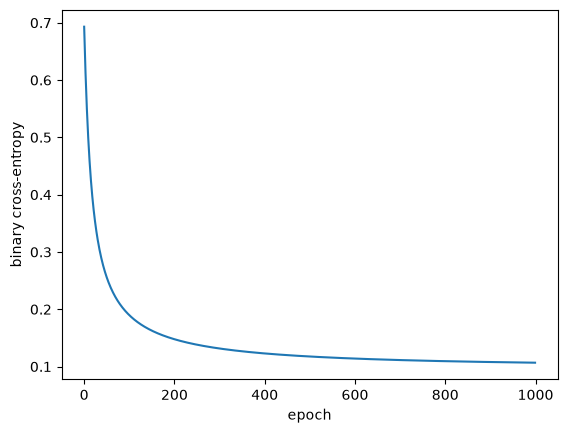

gradient descent  : w = [2.75048127 3.16725821]  b = -0.5848509584425606  test accuracy = 0.9543147208121827
LogisticRegression: w = [2.86348169 3.42482325]  b = -0.6442691564261551  test accuracy = 0.9543147208121827


In [ ]:
mean = train[FEATURES].mean()
std = train[FEATURES].std()
X = ((train[FEATURES] - mean) / std).values
X_test = ((test[FEATURES] - mean) / std).values
y = ytr.values
N = len(y)

w = np.zeros(2)
b = 0.0
losses = []
for epoch in range(N_EPOCHS):
    p = 1 / (1 + np.exp(-(X @ w + b)))
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    w = w - ETA / N * X.T @ (p - y)
    b = b - ETA / N * np.sum(p - y)
    losses.append(loss)

plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.show()

p_test = 1 / (1 + np.exp(-(X_test @ w + b)))
pred_gd = (p_test > 0.5).astype(int)
print("gradient descent  : w =", w, " b =", b, " test accuracy =", accuracy_score(yte, pred_gd))

sk = LogisticRegression()
sk.fit(X, y)
print("LogisticRegression: w =", sk.coef_[0], " b =", sk.intercept_[0], " test accuracy =", sk.score(X_test, yte))

## Alpha or proton?
A stack of silicon detectors measures charged particles (alpha_proton.csv). For each particle we know
its energy energy_MeV and the depth it reaches in the silicon, depth_um. At the same energy, an alpha
stops much sooner than a proton. The label is label_alpha: 1 for an alpha and 0 for a proton. Our goal
is to separate the two.

In [ ]:
# Given parameters
from sklearn.model_selection import StratifiedKFold

FILE            = "data/alpha_proton.csv"
FEATURES        = ["energy_MeV", "depth_um"]
TARGET          = "label_alpha"
TEST_SIZE       = 0.25
K_VALUES        = [1, 3, 5, 11, 21, 51]
DEPTHS          = [1, 2, 3, 5, 10, None]
DEPTH_LABELS    = ["1", "2", "3", "5", "10", "None"]
N_TREES         = 100
N_EPOCHS_NN     = 100
BATCH_SIZE      = 32
LEARNING_RATES  = [1e-4, 1e-3, 1e-2, 1e-1]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Part A: Data



In [ ]:
df = pd.read_csv(FILE)
print("shape:", df.shape)
print(df.isna().sum())
print("duplicated rows:", df.duplicated().sum())

clean = df.drop_duplicates().dropna()
clean = clean[(clean["energy_MeV"] > 0) & (clean["depth_um"] > 0)]
print(clean[TARGET].value_counts())

shape: (1203, 4)
event_id       0
energy_MeV     3
depth_um       4
label_alpha    0
dtype: int64
duplicated rows: 3
label_alpha
0    618
1    570
Name: count, dtype: int64


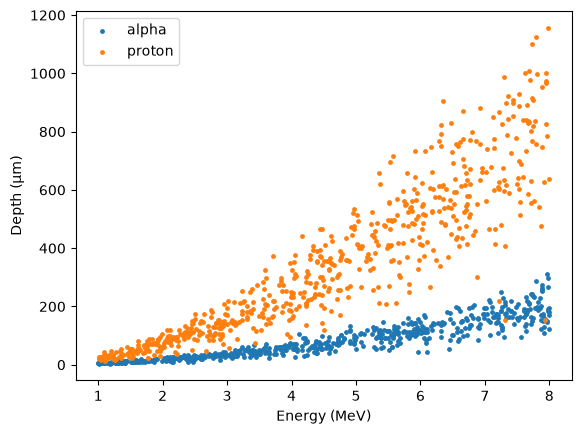

training: 891   test: 297


In [ ]:
alpha = clean[clean[TARGET] == 1]
proton = clean[clean[TARGET] == 0]

plt.scatter(alpha["energy_MeV"], alpha["depth_um"], s=6, label="alpha")
plt.scatter(proton["energy_MeV"], proton["depth_um"], s=6, label="proton")
plt.xlabel("Energy (MeV)")
plt.ylabel("Depth (µm)")
plt.legend()
plt.show()

train, test = train_test_split(clean, test_size=TEST_SIZE, stratify=clean[TARGET], random_state=42)
Xtr = train[FEATURES]
ytr = train[TARGET]
Xte = test[FEATURES]
yte = test[TARGET]
print("training:", len(train), "  test:", len(test))

### Part B: Classical models



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

mean = Xtr.mean()
std = Xtr.std()
Xtr_s = (Xtr - mean) / std
Xte_s = (Xte - mean) / std

knn_raw = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(Xtr_s, ytr)
print("without scaling:", knn_raw.score(Xte, yte))
print("with scaling   :", knn_scaled.score(Xte_s, yte))
print(Xtr.describe())

without scaling: 0.9427609427609428
with scaling   : 0.9831649831649831
       energy_MeV     depth_um
count  891.000000   891.000000
mean     4.572773   222.598429
std      2.081915   236.713626
min      1.000000     3.900000
25%      2.763000    54.900000
50%      4.478000   132.500000
75%      6.390000   299.800000
max      7.996000  1123.300000


k = 1  CV accuracy = 0.984
k = 3  CV accuracy = 0.981
k = 5  CV accuracy = 0.98
k = 11  CV accuracy = 0.975


k = 21  CV accuracy = 0.973
k = 51  CV accuracy = 0.966


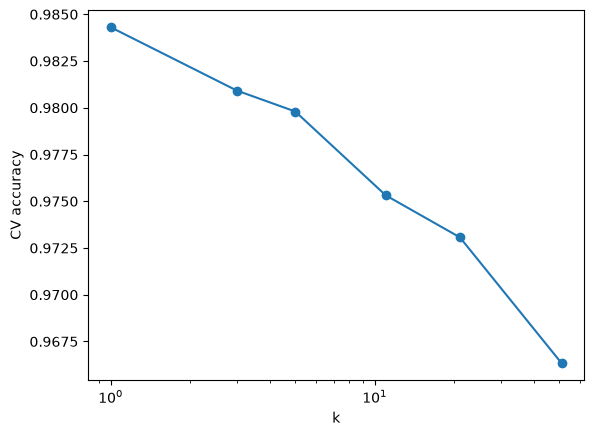

best k: 1


In [ ]:
from sklearn.model_selection import cross_val_score

knn_scores = []
for k in K_VALUES:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, Xtr_s, ytr, cv=cv).mean()
    knn_scores.append(score)
    print("k =", k, " CV accuracy =", round(score, 3))

plt.plot(K_VALUES, knn_scores, "o-")
plt.xscale("log")
plt.xlabel("k")
plt.ylabel("CV accuracy")
plt.show()

best_k = K_VALUES[np.argmax(knn_scores)]
print("best k:", best_k)

In [ ]:
from sklearn.svm import SVC

for kernel in ["linear", "rbf"]:
    svm = SVC(kernel=kernel)
    score = cross_val_score(svm, Xtr_s, ytr, cv=cv).mean()
    print(kernel, " CV accuracy =", round(score, 3))

linear  CV accuracy = 0.972
rbf  CV accuracy = 0.976


depth = 1  training = 0.776  CV = 0.774
depth = 2  training = 0.781  CV = 0.754


depth = 3  training = 0.925  CV = 0.912
depth = 5  training = 0.991  CV = 0.967


depth = 10  training = 1.0  CV = 0.973
depth = None  training = 1.0  CV = 0.973


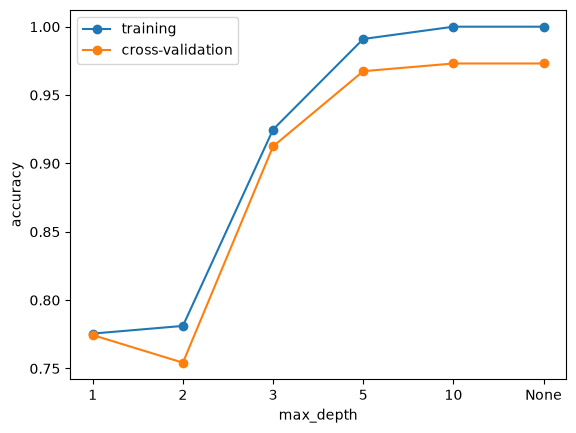

random forest CV accuracy: 0.9865294080723119


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

train_acc = []
cv_acc = []
for d in DEPTHS:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_score = cross_val_score(tree, Xtr, ytr, cv=cv).mean()
    tree.fit(Xtr, ytr)
    train_score = tree.score(Xtr, ytr)
    cv_acc.append(cv_score)
    train_acc.append(train_score)
    print("depth =", d, " training =", round(train_score, 3), " CV =", round(cv_score, 3))

plt.plot(DEPTH_LABELS, train_acc, "o-", label="training")
plt.plot(DEPTH_LABELS, cv_acc, "o-", label="cross-validation")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()

forest = RandomForestClassifier(n_estimators=N_TREES, random_state=42)
print("random forest CV accuracy:", cross_val_score(forest, Xtr, ytr, cv=cv).mean())

### Part C: Neural network



In [ ]:
from tensorflow import keras

keras.utils.set_random_seed(0)
net = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
net.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
net.fit(Xtr_s, ytr, epochs=N_EPOCHS_NN, batch_size=BATCH_SIZE, verbose=0)

print("parameters:", net.count_params())
test_loss, test_acc = net.evaluate(Xte_s, yte, verbose=0)
print("test accuracy:", test_acc)

I0000 00:00:1794237993.988749     168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794237996.256668     168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


parameters: 337
test accuracy: 0.9764309525489807


lr = 0.0001  test accuracy = 0.943


lr = 0.001  test accuracy = 0.976


lr = 0.01  test accuracy = 0.987


lr = 0.1  test accuracy = 0.987


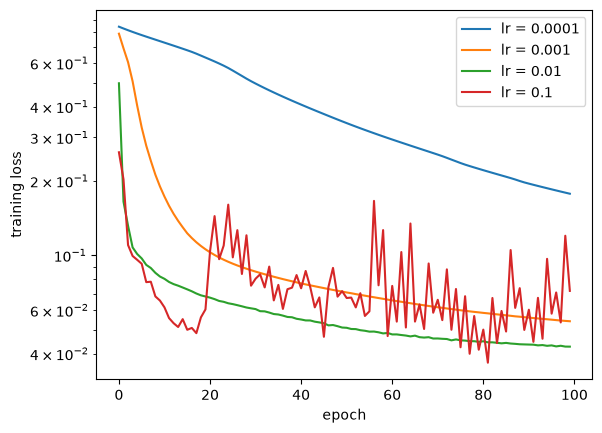

In [ ]:
for lr in LEARNING_RATES:
    keras.utils.set_random_seed(0)
    model = keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(Xtr_s, ytr, epochs=N_EPOCHS_NN, batch_size=BATCH_SIZE, verbose=0)
    test_loss, test_acc = model.evaluate(Xte_s, yte, verbose=0)
    print("lr =", lr, " test accuracy =", round(test_acc, 3))
    plt.plot(history.history["loss"], label="lr = " + str(lr))

plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("training loss")
plt.legend()
plt.show()

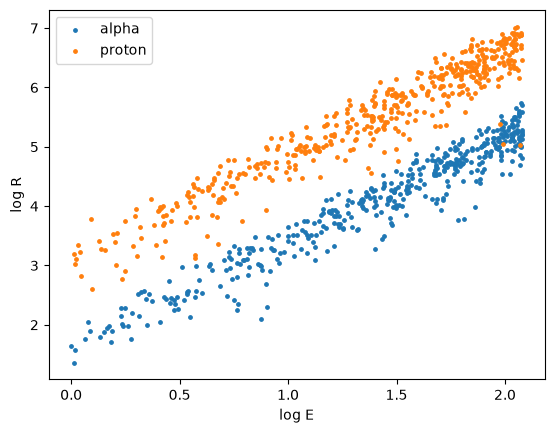

test accuracy, logistic regression on logs: 0.9865319865319865
test accuracy, network (Q7)               : 0.9764309525489807
estimated exponent: 1.6430830796553502


In [ ]:
log_train = np.log(Xtr)
log_test = np.log(Xte)

log_alpha = log_train[ytr == 1]
log_proton = log_train[ytr == 0]
plt.scatter(log_alpha["energy_MeV"], log_alpha["depth_um"], s=6, label="alpha")
plt.scatter(log_proton["energy_MeV"], log_proton["depth_um"], s=6, label="proton")
plt.xlabel("log E")
plt.ylabel("log R")
plt.legend()
plt.show()

logreg = LogisticRegression()
logreg.fit(log_train, ytr)
print("test accuracy, logistic regression on logs:", logreg.score(log_test, yte))
print("test accuracy, network (Q7)               :", net.evaluate(Xte_s, yte, verbose=0)[1])

w1 = logreg.coef_[0][0]
w2 = logreg.coef_[0][1]
exponent = -w1 / w2
print("estimated exponent:", exponent)

### Part D: Conclusion



In [ ]:
from sklearn.metrics import f1_score

knn_final = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr_s, ytr)
svm_lin_final = SVC(kernel="linear").fit(Xtr_s, ytr)
svm_rbf_final = SVC(kernel="rbf").fit(Xtr_s, ytr)
tree_final = DecisionTreeClassifier(max_depth=10, random_state=42).fit(Xtr, ytr)
forest.fit(Xtr, ytr)
pred_net = (net.predict(Xte_s, verbose=0) > 0.5).astype(int).ravel()

names = ["kNN", "SVM linear", "SVM rbf", "Tree", "Forest", "Network"]
preds = [knn_final.predict(Xte_s), svm_lin_final.predict(Xte_s), svm_rbf_final.predict(Xte_s), tree_final.predict(Xte), forest.predict(Xte), pred_net]
for i in range(len(names)):
    pred = preds[i]
    print(names[i], ": accuracy", round(accuracy_score(yte, pred), 3), " precision", round(precision_score(yte, pred), 3),
          " recall", round(recall_score(yte, pred), 3), " F1", round(f1_score(yte, pred), 3))

kNN : accuracy 0.98  precision 0.972  recall 0.986  F1 0.979
SVM linear : accuracy 0.97  precision 0.965  recall 0.972  F1 0.968
SVM rbf : accuracy 0.976  precision 0.953  recall 1.0  F1 0.976
Tree : accuracy 0.983  precision 0.986  recall 0.979  F1 0.982
Forest : accuracy 0.976  precision 0.972  recall 0.979  F1 0.975
Network : accuracy 0.976  precision 0.972  recall 0.979  F1 0.975


>
>
> | Model | Accuracy | Precision | Recall | F1 |
> |---|---|---|---|---|
> | kNN (k = 1) | 0.980 | 0.972 | 0.986 | 0.979 |
> | SVM linear | 0.970 | 0.965 | 0.972 | 0.968 |
> | SVM rbf | 0.976 | 0.953 | 1.000 | 0.976 |
> | Tree (depth 10) | **0.983** | 0.986 | 0.979 | **0.982** |
> | Forest | 0.976 | 0.972 | 0.979 | 0.975 |
> | Network | 0.976 | 0.972 | 0.979 | 0.975 |
>
> All non-linear models reach **0.976–0.983**. With 297 test particles one error changes the accuracy by 0.003, so these differences (2 to 5 particles) are not significant: any of them is a good choice; the tree has the best F1. (Q9 shows that a logistic regression on log E and log R does even better.)
>
> The linear SVM is a little worse because the true border follows depth ∝ E^1.75: it is **curved**, and a straight line in the (E, R) plane can only approximate it. Its errors are at low energy, where the bands are closest and the border bends most.